A procedural animation scene for ``python -m svgwriter animate``.

The script defines a drawing (``doc``) and an ``update(doc, seconds)`` function that moves it; the
animate command renders one frame per time step.

    python -m svgwriter animate examples/orbit_scene.py -o orbit.gif --renderer skia
    python orbit_scene.py [OUTPUT_DIR]      writes the first frame as SVG

In [1]:
import math
import sys
import tempfile
from pathlib import Path

import svgwriter as svg

The static scene: a sun, an orbit path and a planet. The `FPS`, `DURATION` and `RENDERER`
constants are read by `svgwriter animate` as defaults.

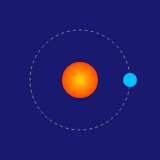

In [2]:
SIZE = 160
CENTER = SIZE / 2
ORBIT = 50
FPS = 24
DURATION = 2.0
RENDERER = "skia"

doc = svg.Document(SIZE, SIZE)
glow = doc.radial_gradient(svg.Stop(0, "gold"), svg.Stop(1, "orangered"))
doc.rect(0, 0, SIZE, SIZE, fill="midnightblue")
doc.circle(CENTER, CENTER, ORBIT, fill="none", stroke="slategray", stroke_dasharray=(3, 3))
doc.circle(CENTER, CENTER, 18, fill=glow)
planet = doc.circle(CENTER + ORBIT, CENTER, 7, fill="deepskyblue")
doc

`update` sets the planet's position for a given time. Calling it with a quarter of the duration
moves the planet a quarter of the way round.

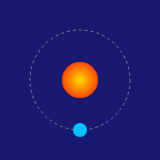

In [3]:
def update(doc: svg.Document, seconds: float) -> None:
    angle = 2 * math.pi * seconds / DURATION
    planet.cx = CENTER + ORBIT * math.cos(angle)
    planet.cy = CENTER + ORBIT * math.sin(angle)


update(doc, DURATION / 4)
doc

Back to the first frame and save it. Pass a folder as the first argument to choose where it goes.
This cell is skipped when `svgwriter animate` loads the script.

In [4]:
if __name__ == "__main__":
    update(doc, 0)
    args = sys.argv[1:2]
    out = Path(args[0]) if args and not args[0].startswith("-") else Path(tempfile.mkdtemp(prefix="svgwriter-"))
    doc.save(out / "orbit_frame0.svg")
    print("saved orbit_frame0.svg")

saved orbit_frame0.svg
